# 03 · Model Comparison: Can We Predict Who Will Churn?

Notebook 01 showed which characteristics are *associated* with churn. This notebook asks a different question: **given a customer's profile, how well can we predict whether they will leave?**

We compare four model families, from simplest to most flexible:

| Model | Why it is included |
|---|---|
| **Logistic Regression** | Baseline. Simple, fast, interpretable coefficients, but assumes each feature has a straight-line (log-odds) effect |
| **Decision Tree** | Produces human-readable rules ("if age > X and inactive then …") and can capture non-linear patterns |
| **Random Forest** | Averages many trees; usually more accurate and stable than a single tree |
| **XGBoost** | Gradient-boosted trees; often the strongest model on tabular data like this |

The neural network (ANN) from the original project is built in notebook 04 and added to the same comparison.

### A fair comparison
* **Same data:** every model uses the identical train/test split from notebook 02 and the identical preprocessing pipeline.
* **Same tuning procedure:** each model gets a small hyperparameter grid, evaluated with **5-fold stratified cross-validation on the training set only**, using ROC-AUC as the selection metric.
* **Untouched test set:** the 2,000 test customers are used *only* for the final evaluation, never for choosing models or settings.

In [1]:
import json
import sys
import warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    fbeta_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

from src.churn_utils import (
    COLOR_MUTED,
    METRICS_PATH,
    MODEL_METADATA_PATH,
    MODEL_PATH,
    MODELS_DIR,
    RANDOM_STATE,
    REPORTS_DIR,
    TEST_PREDICTIONS_PATH,
    build_preprocessor,
    classification_metrics,
    load_train_test,
    save_figure,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
set_plot_style()

X_train, X_test, y_train, y_test, test_customer_ids = load_train_test()
print(f"Train: {X_train.shape}, churn rate {y_train.mean():.1%}")
print(f"Test:  {X_test.shape}, churn rate {y_test.mean():.1%}")

Train: (8000, 10), churn rate 20.4%
Test:  (2000, 10), churn rate 20.3%


## 1. Define the models and their tuning grids

Each model is wrapped in a `Pipeline` with the shared preprocessor, so encoding and scaling are re-fit inside every cross-validation fold (no leakage). The grids are kept deliberately small: the goal is a fair, explainable comparison, not squeezing out the last 0.1%.

In [2]:
candidate_models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000),
        {"model__C": [0.01, 0.1, 1, 10]},  # regularisation strength
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 20, 50]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
        {"model__max_depth": [6, 10, None], "model__min_samples_leaf": [1, 5, 10]},
    ),
    "XGBoost": (
        XGBClassifier(subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
                      random_state=RANDOM_STATE, n_jobs=-1),
        {"model__max_depth": [3, 4, 5], "model__learning_rate": [0.03, 0.1],
         "model__n_estimators": [200, 400]},
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 2. Tune each model with cross-validation

In [3]:
fitted_models, cv_summary = {}, []
for name, (estimator, grid) in candidate_models.items():
    pipeline = Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])
    search = GridSearchCV(pipeline, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)
    fitted_models[name] = search.best_estimator_  # refit on the full training set
    cv_summary.append({
        "Model": name,
        "CV ROC-AUC (mean)": search.best_score_,
        "CV ROC-AUC (std)": search.cv_results_["std_test_score"][search.best_index_],
        "Best parameters": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
    })

cv_summary = pd.DataFrame(cv_summary).sort_values("CV ROC-AUC (mean)", ascending=False)
cv_summary.style.format({"CV ROC-AUC (mean)": "{:.3f}", "CV ROC-AUC (std)": "{:.3f}"}).hide(axis="index")

Model,CV ROC-AUC (mean),CV ROC-AUC (std),Best parameters
XGBoost,0.866,0.010,"{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 400}"
Random Forest,0.860,0.010,"{'max_depth': 10, 'min_samples_leaf': 5}"
Decision Tree,0.838,0.011,"{'max_depth': 6, 'min_samples_leaf': 20}"
Logistic Regression,0.766,0.019,{'C': 0.01}


**Cross-validation results (training data only):**
* The tree-based models clearly outperform logistic regression: **XGBoost 0.866**, Random Forest 0.860, Decision Tree 0.838, versus **0.766** for Logistic Regression.
* The fold-to-fold standard deviation is about 0.01, so the gap between XGBoost and Random Forest (0.006) is **within normal variation**. The two are effectively tied. The gap to logistic regression (~0.10) is large and real.
* Why does logistic regression lag? Notebook 01 showed that churn has **non-linear** relationships with age (peaks at 50–59) and number of products (U-shaped). A linear model can't represent "2 products is good but 3 is bad" without manual feature engineering. Tree models learn these patterns automatically.

## 3. Evaluate on the held-out test set

We now score each tuned model on the 2,000 unseen test customers. Metrics are computed at the default **0.5 probability threshold** (a customer is flagged as a churner if predicted probability ≥ 50%).

We also include a **naive baseline** that predicts "no one churns". It shows what accuracy looks like with zero predictive skill.

In [4]:
naive = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

test_probabilities = {name: model.predict_proba(X_test)[:, 1] for name, model in fitted_models.items()}
results = {"Naive baseline (no one churns)": classification_metrics(y_test, naive.predict_proba(X_test)[:, 1])}
results.update({name: classification_metrics(y_test, p) for name, p in test_probabilities.items()})

results = pd.DataFrame(results).T
results.style.format("{:.3f}").highlight_max(axis=0, subset=["Precision", "Recall", "F1", "ROC-AUC"],
                                             props="font-weight:bold; background-color:#e8f0fb")

,Accuracy,Precision,Recall,F1,ROC-AUC
Naive baseline (no one churns),0.796,0.000,0.000,0.000,0.500
Logistic Regression,0.807,0.617,0.143,0.232,0.776
Decision Tree,0.861,0.778,0.440,0.562,0.846
Random Forest,0.867,0.834,0.432,0.570,0.862
XGBoost,0.869,0.787,0.489,0.603,0.871


**Test-set results (2,000 unseen customers, 407 of whom churned):**
* **XGBoost** has the best ROC-AUC (**0.871**), recall (0.489) and F1 (0.603) on the test set. Random Forest is close behind (ROC-AUC 0.862) with slightly higher precision (0.834).
* The test results agree with cross-validation (XGBoost ≈ 0.87 in both), which suggests the models are **not overfitting** to the training data.
* **ROC-AUC of 0.87** means: if you pick one random churner and one random non-churner, the model ranks the churner as higher-risk about 87% of the time. That's good, but not perfect. A meaningful share of churn isn't explained by the 10 available variables.
* **Logistic regression has decent accuracy (0.807) but catches only 14% of churners** at the 0.5 threshold, a clear example of why accuracy is misleading (see below).

### Why accuracy alone is misleading here

The naive "no one churns" baseline scores **79.6% accuracy** while identifying **zero** churners. Every model looks impressive next to that number, but:
* Logistic regression's 80.7% accuracy is barely better than doing nothing, and it misses 86% of churners.
* XGBoost's 86.9% accuracy sounds high, yet at the 0.5 threshold it **still misses about half of the churners** (recall 0.489).

When 80% of customers stay, accuracy is dominated by the easy "stays" predictions. For a retention team, the questions that matter are about the **churn class**:
* **Recall:** *of the customers who actually leave, how many did we flag?* (missed churners = lost customers)
* **Precision:** *of the customers we flagged, how many really were going to leave?* (wasted retention effort)
* **ROC-AUC:** *how well does the model rank customers by risk overall?* (independent of any threshold)

## 4. Confusion matrices: what the errors look like

For the churn problem, the two kinds of error have very different business meanings:

| | Predicted: stays | Predicted: churns |
|---|---|---|
| **Actually stays** | ✅ True negative | ⚠️ **False positive**: the bank spends retention effort (e.g. a discount or a call) on a customer who would have stayed anyway |
| **Actually churns** | ❌ **False negative**: a customer leaves *without the bank ever trying to keep them* | ✅ True positive: a churner identified in time to act |

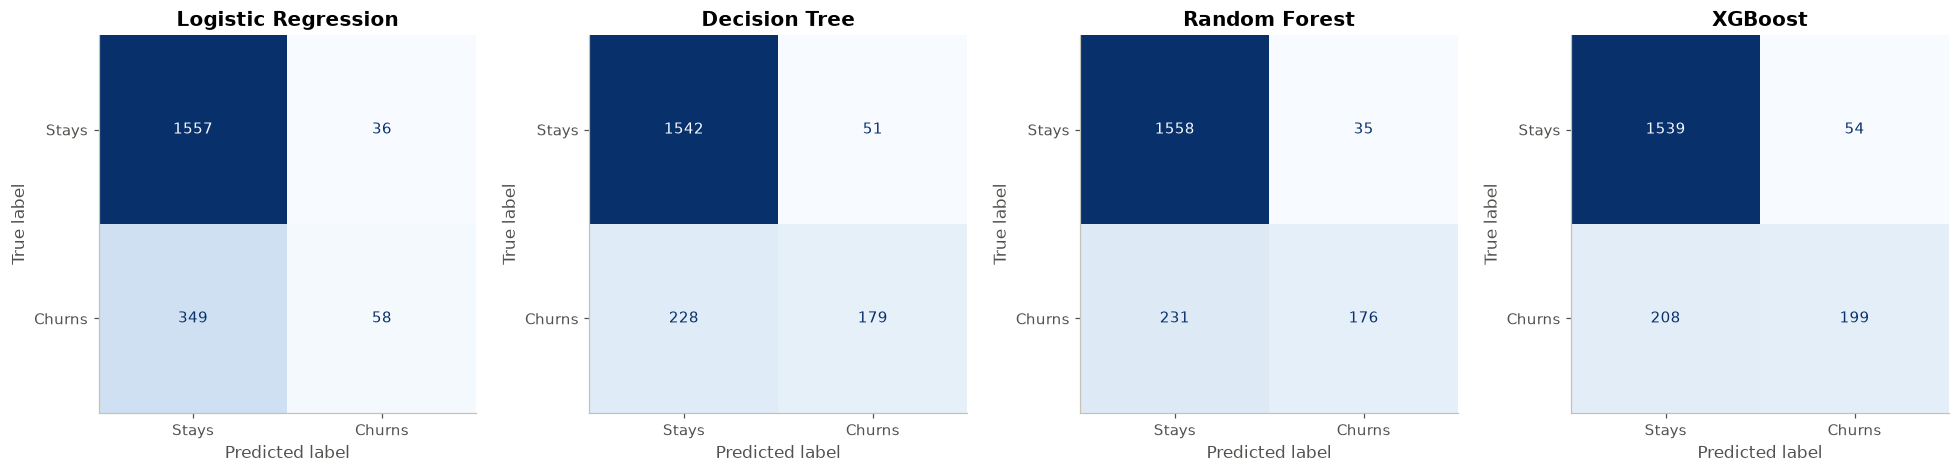

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (name, probabilities) in zip(axes, test_probabilities.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, (probabilities >= 0.5).astype(int), display_labels=["Stays", "Churns"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
save_figure(fig, "03_confusion_matrices")
plt.show()

At the default 0.5 threshold, all models are **conservative**. They rarely raise false alarms, but they miss many churners:

| Model | Churners caught (TP) | Churners missed (FN) | False alarms (FP) |
|---|---|---|---|
| Logistic Regression | 58 | **349** | 36 |
| Decision Tree | 179 | 228 | 51 |
| Random Forest | 176 | 231 | 35 |
| XGBoost | **199** | **208** | 54 |

Even the best model misses 208 of the 407 churners. For a retention use-case that's the bigger problem, because each missed churner is a customer the bank never gets the chance to keep. This motivates lowering the threshold (Section 7).

## 5. ROC and precision-recall curves

A single threshold hides part of the picture. The **ROC curve** shows the trade-off between catching churners (true-positive rate) and false alarms (false-positive rate) across *all* thresholds. The **precision-recall curve** is often more informative when the positive class is rare (here 20%).

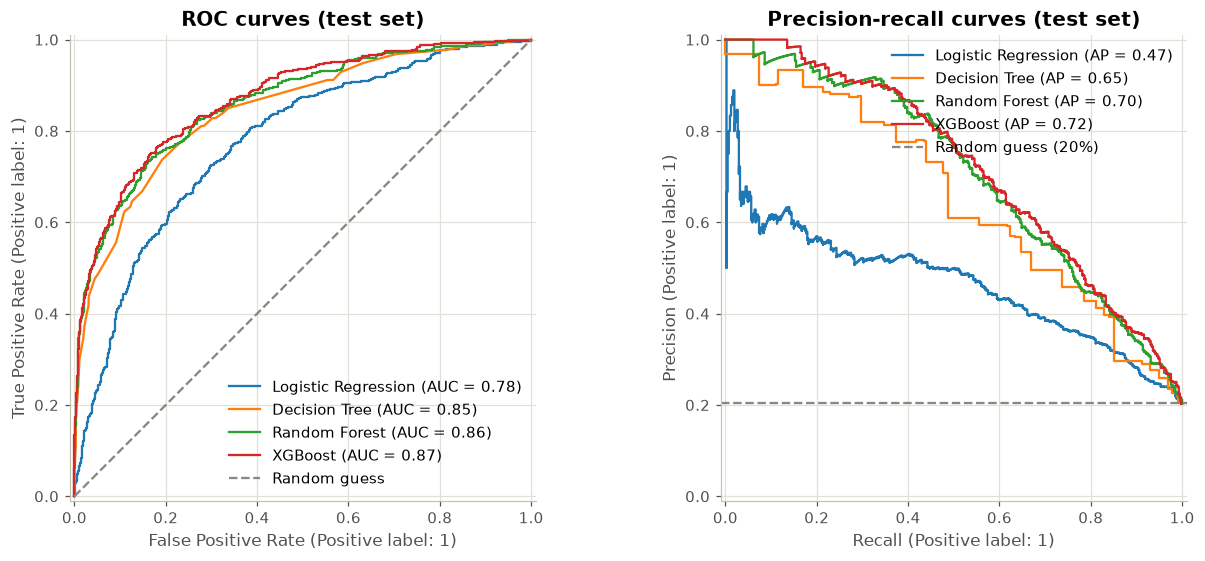

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, probabilities in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, probabilities, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probabilities, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], linestyle="--", color=COLOR_MUTED, label="Random guess")
axes[0].set_title("ROC curves (test set)")
axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), linestyle="--", color=COLOR_MUTED, label=f"Random guess ({y_test.mean():.0%})")
axes[1].set_title("Precision-recall curves (test set)")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(True)
save_figure(fig, "03_roc_pr_curves")
plt.show()

* The three tree-based models have similar curves, with XGBoost and Random Forest slightly ahead of the single decision tree. Logistic regression is clearly below them across the whole range.
* The precision-recall curves show the core trade-off: **catching more churners (higher recall) means accepting more false alarms (lower precision)**. No model achieves both high precision and high recall, which is typical for churn problems where many leavers look similar to stayers on the available data.

## 6. Interpreting the simpler models

Before going further with the best model, the two simpler models tell us something useful on their own.

### 6.1 Logistic regression coefficients
Coefficients are shown as **odds ratios per one standard deviation** (for numeric features) or per category (for 0/1 features). An odds ratio above 1 means higher values are associated with *higher* churn odds, and below 1 with *lower* churn odds, holding the other features constant. These are associations learned from the data, not causal effects.

In [7]:
logreg = fitted_models["Logistic Regression"]
odds_ratios = pd.DataFrame({
    "Feature": logreg.named_steps["preprocess"].get_feature_names_out(),
    "Coefficient": logreg.named_steps["model"].coef_[0],
})
odds_ratios["Odds ratio"] = np.exp(odds_ratios["Coefficient"])
odds_ratios = odds_ratios.sort_values("Coefficient", ascending=False).reset_index(drop=True)
odds_ratios.style.format({"Coefficient": "{:+.2f}", "Odds ratio": "{:.2f}"}).hide(axis="index")

Feature,Coefficient,Odds ratio
Age,+0.65,1.91
Geography_Germany,+0.41,1.50
Balance,+0.17,1.19
EstimatedSalary,+0.04,1.05
Tenure,-0.01,0.99
HasCrCard,-0.05,0.96
NumOfProducts,-0.06,0.94
CreditScore,-0.08,0.92
Geography_Spain,-0.17,0.84
Geography_France,-0.23,0.79


Reading the strongest coefficients (all are associations, holding other features fixed):
* **Age** (odds ratio 1.91 per standard deviation, about 10.5 years): older customers have higher churn odds.
* **Geography_Germany** (1.50): higher churn odds than the reference countries.
* **IsActiveMember** (0.49): active customers have about **half the churn odds** of inactive ones.
* **Gender_Male** (0.68): lower churn odds for male customers.
* **NumOfProducts** gets an odds ratio of only 0.94, *even though it was the variable most strongly associated with churn in notebook 01*. A single linear coefficient can't capture "2 is good, 3–4 are bad", which is exactly why logistic regression underperforms here.

### 6.2 The decision tree's top rules
The first few splits of the tuned decision tree show which questions the model asks first. Numeric thresholds are shown on the *standardised* scale, so we translate the key ones back to original units below the chart.

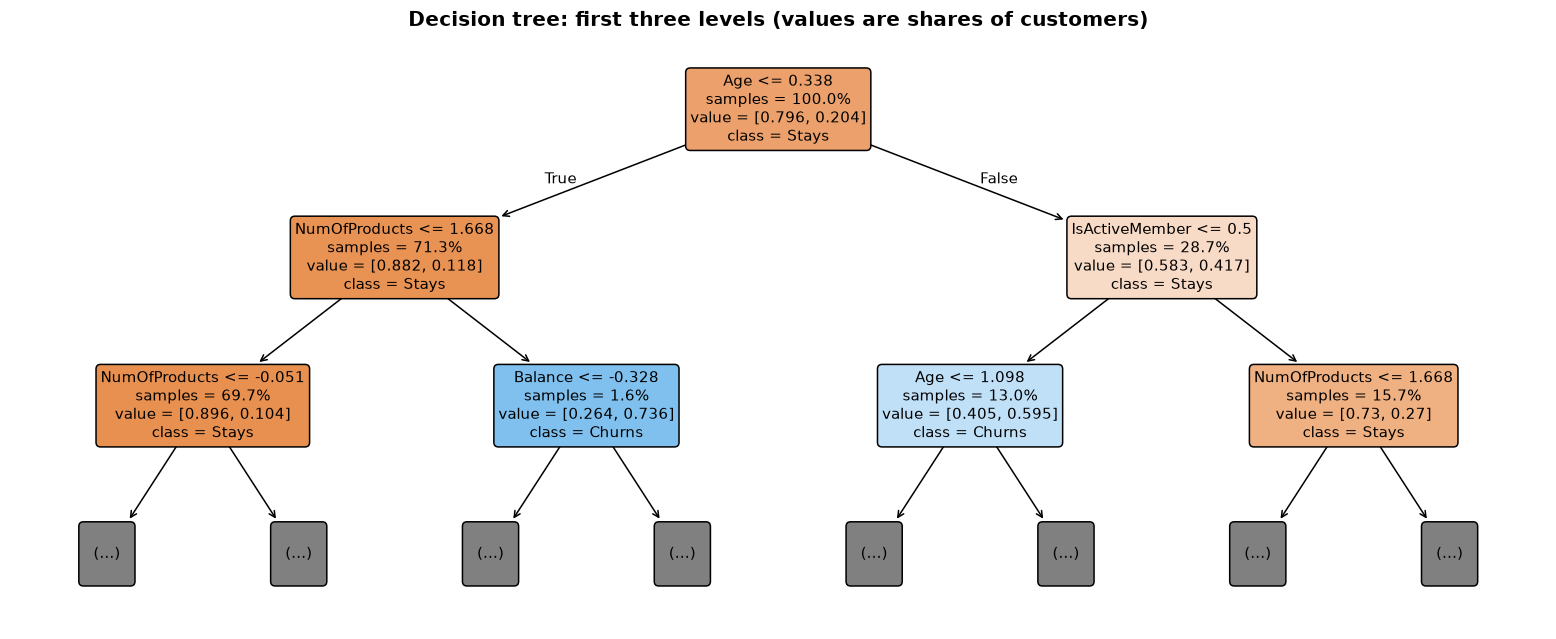

In [8]:
tree_pipeline = fitted_models["Decision Tree"]
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(
    tree_pipeline.named_steps["model"],
    feature_names=tree_pipeline.named_steps["preprocess"].get_feature_names_out(),
    class_names=["Stays", "Churns"], max_depth=2, filled=True, rounded=True,
    proportion=True, impurity=False, fontsize=10, ax=ax,
)
ax.set_title("Decision tree: first three levels (values are shares of customers)")
save_figure(fig, "03_decision_tree_rules")
plt.show()

In [9]:
# Translate the standardised split thresholds back into original units
tree_model = tree_pipeline.named_steps["model"].tree_
feature_names = tree_pipeline.named_steps["preprocess"].get_feature_names_out()
scaler = tree_pipeline.named_steps["preprocess"].named_transformers_["numeric"]
numeric_names = list(scaler.feature_names_in_)

def split_in_original_units(node):
    feature = feature_names[tree_model.feature[node]]
    threshold = tree_model.threshold[node]
    if feature in numeric_names:
        i = numeric_names.index(feature)
        threshold = threshold * scaler.scale_[i] + scaler.mean_[i]
    return f"{feature} <= {threshold:,.1f}"

# Nodes at depth 0 and 1 (root and its two children)
root, left, right = 0, tree_model.children_left[0], tree_model.children_right[0]
for label, node in [("Root split", root), ("Left child split", left), ("Right child split", right)]:
    print(f"{label:<18}: {split_in_original_units(node)}")

Root split        : Age <= 42.5
Left child split  : NumOfProducts <= 2.5
Right child split : IsActiveMember <= 0.5


The tree's first questions match the EDA closely:
1. **Is the customer older than about 42?** This is the single most informative split.
2. For **younger customers**, the next question is **whether they hold 3 or more products**.
3. For **older customers**, the next question is **whether they are active members**.

This gives the business a simple, explainable rule of thumb: *older inactive customers and customers with 3+ products are where churn concentrates*. The more complex models refine these rules with many more splits.

## 7. Choosing a decision threshold for the business

The 0.5 threshold is a statistical default, not a business decision. For retention, **missing a churner (false negative) is usually more costly than contacting a customer who would have stayed (false positive)**:
* A missed churner means losing the customer's whole relationship (balances, future fees and interest).
* A false alarm costs the price of one contact or offer.

The dataset contains **no cost information** (offer costs, customer revenue), so we can't compute the money-optimal threshold. Instead we set an explicit, easy-to-communicate **business target**:

> **Recall target: identify at least 70% of the customers who will churn.**

We then choose the *highest* threshold that still meets that target, which keeps false alarms as low as possible while catching 7 in 10 churners. The 70% figure is an assumption for illustration; in practice it would be agreed with the retention team based on budget and capacity.

To avoid tuning on the test set, the threshold is chosen using **out-of-fold predictions on the training set** (each training customer is scored by a model that did not see them), and then checked once on the test set.

In [10]:
RECALL_TARGET = 0.70

best_model_name = cv_summary.iloc[0]["Model"]  # selected by cross-validated ROC-AUC, not by test results
best_model = fitted_models[best_model_name]
print(f"Selected model (highest CV ROC-AUC): {best_model_name}")

oof_probabilities = cross_val_predict(clone(best_model), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

def threshold_stats(threshold):
    flagged = oof_probabilities >= threshold
    return {"Threshold": threshold,
            "Precision": precision_score(y_train, flagged),
            "Recall": recall_score(y_train, flagged),
            "F1": fbeta_score(y_train, flagged, beta=1),
            "Customers flagged": flagged.mean()}

# Highest threshold (on a 0.01 grid) whose out-of-fold recall still meets the target
fine_grid = pd.DataFrame([threshold_stats(t) for t in np.round(np.arange(0.05, 0.96, 0.01), 2)])
decision_threshold = float(fine_grid.loc[fine_grid["Recall"] >= RECALL_TARGET, "Threshold"].max())
print(f"Highest threshold with out-of-fold recall >= {RECALL_TARGET:.0%}: {decision_threshold}")

# Show the trade-off at a few readable thresholds, plus the chosen one
shown = sorted(set(np.round(np.arange(0.10, 0.65, 0.05), 2)) | {decision_threshold})
threshold_table = fine_grid[fine_grid["Threshold"].isin(shown)]
threshold_table.style.format({"Threshold": "{:.2f}", "Precision": "{:.3f}", "Recall": "{:.3f}",
                              "F1": "{:.3f}", "Customers flagged": "{:.1%}"}).hide(axis="index")

Selected model (highest CV ROC-AUC): XGBoost


Highest threshold with out-of-fold recall >= 70%: 0.25


Threshold,Precision,Recall,F1,Customers flagged
0.10,0.355,0.896,0.508,51.4%
0.15,0.433,0.829,0.569,39.0%
0.20,0.502,0.756,0.604,30.7%
0.25,0.559,0.707,0.624,25.8%
0.30,0.613,0.653,0.632,21.7%
0.35,0.659,0.601,0.629,18.6%
0.40,0.702,0.559,0.622,16.2%
0.45,0.736,0.509,0.601,14.1%
0.50,0.771,0.467,0.582,12.3%
0.55,0.798,0.426,0.556,10.9%


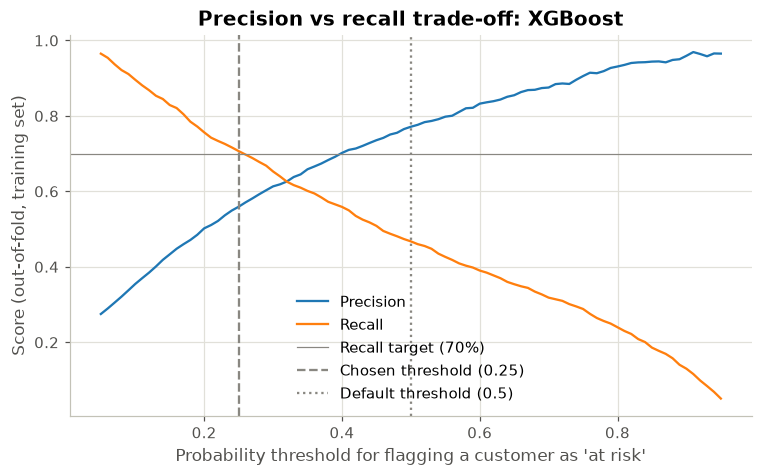

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(fine_grid["Threshold"], fine_grid["Precision"], label="Precision")
ax.plot(fine_grid["Threshold"], fine_grid["Recall"], label="Recall")
ax.axhline(RECALL_TARGET, color=COLOR_MUTED, linewidth=0.8, label=f"Recall target ({RECALL_TARGET:.0%})")
ax.axvline(decision_threshold, color=COLOR_MUTED, linestyle="--", label=f"Chosen threshold ({decision_threshold})")
ax.axvline(0.5, color=COLOR_MUTED, linestyle=":", label="Default threshold (0.5)")
ax.set_xlabel("Probability threshold for flagging a customer as 'at risk'")
ax.set_ylabel("Score (out-of-fold, training set)")
ax.set_title(f"Precision vs recall trade-off: {best_model_name}")
ax.legend()
ax.grid(True)
save_figure(fig, "03_threshold_tradeoff")
plt.show()

In [12]:
best_test_probabilities = test_probabilities[best_model_name]
threshold_comparison = pd.DataFrame({
    "Default threshold (0.5)": classification_metrics(y_test, best_test_probabilities, 0.5),
    f"Business threshold ({decision_threshold})": classification_metrics(y_test, best_test_probabilities, decision_threshold),
}).T
threshold_comparison["Customers flagged"] = [(best_test_probabilities >= t).sum() for t in (0.5, decision_threshold)]
threshold_comparison.style.format({c: "{:.3f}" for c in threshold_comparison.columns if c != "Customers flagged"})

,Accuracy,Precision,Recall,F1,ROC-AUC,Customers flagged
Default threshold (0.5),0.869,0.787,0.489,0.603,0.871,253
Business threshold (0.25),0.827,0.557,0.720,0.628,0.871,526


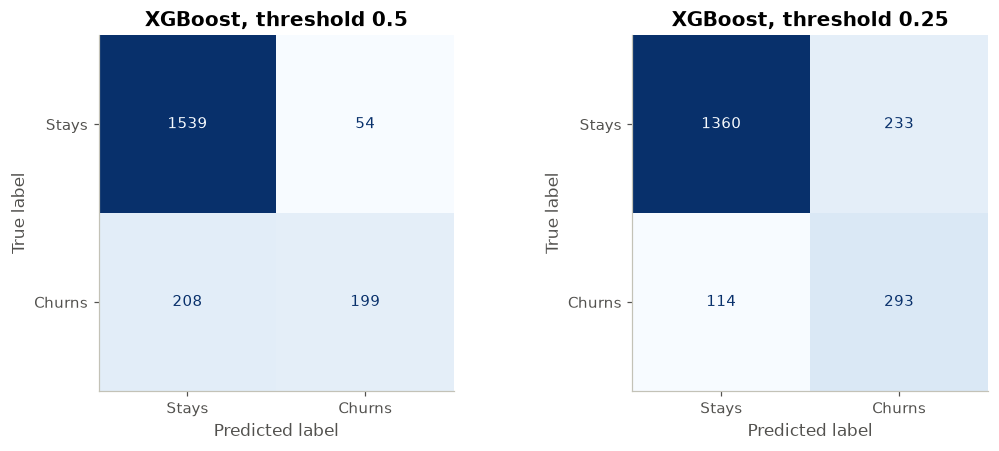

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, t in zip(axes, (0.5, decision_threshold)):
    ConfusionMatrixDisplay.from_predictions(y_test, (best_test_probabilities >= t).astype(int),
                                            display_labels=["Stays", "Churns"], cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(f"{best_model_name}, threshold {t}")
    ax.grid(False)
plt.tight_layout()
save_figure(fig, "03_threshold_confusion")
plt.show()

**Lowering the threshold from 0.5 to 0.25 on the test set:**

| | Threshold 0.5 | Threshold 0.25 |
|---|---|---|
| Churners caught (of 407) | 199 (49%) | **293 (72%)** |
| Churners missed | 208 | **114** |
| False alarms | 54 | 233 |
| Customers flagged for outreach | 253 | 526 |
| Precision | 0.79 | 0.56 |

* The bank catches **94 more churners**, at the cost of **179 more false alarms**. Roughly 1 in 2 flagged customers is a true churner instead of 4 in 5.
* Accuracy *drops* (0.869 → 0.827) even though the model is arguably *more useful* for retention. This is the accuracy trap in action.
* The test-set recall (0.72) is close to the 70% target set on training data, so the threshold generalises.
* Whether this trade-off is worth it depends on the **cost of an intervention vs the value of a retained customer**, which the dataset doesn't contain. If outreach is cheap (an email, an app notification), a low threshold makes sense. If it's expensive (a relationship manager's time, a fee waiver), a higher threshold or the prioritisation in notebook 05 is more appropriate.

## 8. Save results for the next notebooks and the dashboard

In [14]:
MODELS_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)

# Selected model (preprocessing + classifier in one pipeline) for notebook 05 and the dashboard
joblib.dump(best_model, MODEL_PATH)

metadata = {
    "model_name": best_model_name,
    "best_parameters": {k: (v if not isinstance(v, np.generic) else v.item())
                        for k, v in cv_summary.iloc[0]["Best parameters"].items()},
    "cv_roc_auc": round(float(cv_summary.iloc[0]["CV ROC-AUC (mean)"]), 4),
    "decision_threshold": decision_threshold,
    "threshold_rule": f"highest threshold with out-of-fold training recall >= {RECALL_TARGET}",
    "test_metrics_default_threshold": {k: round(float(v), 4) for k, v in threshold_comparison.iloc[0].items()},
    "test_metrics_business_threshold": {k: round(float(v), 4) for k, v in threshold_comparison.iloc[1].items()},
    "library_versions": {"scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__},
}
MODEL_METADATA_PATH.write_text(json.dumps(metadata, indent=2))

# Test-set metrics and predictions (notebook 04 adds the ANN to these)
results.drop(index="Naive baseline (no one churns)").round(4).rename_axis("Model").to_csv(METRICS_PATH)
predictions = pd.DataFrame({"CustomerId": test_customer_ids, "Exited": y_test})
for name, probabilities in test_probabilities.items():
    predictions[name] = probabilities.round(5)
predictions.to_csv(TEST_PREDICTIONS_PATH, index=False)

print(json.dumps(metadata, indent=2))

{
  "model_name": "XGBoost",
  "best_parameters": {
    "learning_rate": 0.03,
    "max_depth": 3,
    "n_estimators": 400
  },
  "cv_roc_auc": 0.8659,
  "decision_threshold": 0.25,
  "threshold_rule": "highest threshold with out-of-fold training recall >= 0.7",
  "test_metrics_default_threshold": {
    "Accuracy": 0.869,
    "Precision": 0.7866,
    "Recall": 0.4889,
    "F1": 0.603,
    "ROC-AUC": 0.8707,
    "Customers flagged": 253.0
  },
  "test_metrics_business_threshold": {
    "Accuracy": 0.8265,
    "Precision": 0.557,
    "Recall": 0.7199,
    "F1": 0.6281,
    "ROC-AUC": 0.8707,
    "Customers flagged": 526.0
  },
  "library_versions": {
    "scikit-learn": "1.9.1",
    "xgboost": "3.4.1"
  }
}


## Summary
* **Selected model: XGBoost.** It was chosen by cross-validated ROC-AUC (0.866) *before* looking at the test set, and confirmed on the test set (ROC-AUC 0.871). Random Forest performs almost as well. Logistic regression is clearly weaker because churn has non-linear relationships with age and number of products.
* **At the default 0.5 threshold** XGBoost reaches 0.869 accuracy but only 0.489 recall. It misses about half of the churners.
* **With a business threshold of 0.25** (target: catch ≥ 70% of churners), test recall rises to **0.720** with precision **0.557**.
* **Honest limitations:** ROC-AUC of ~0.87 means the model ranks customers well but makes many individual mistakes. Performance is measured on one dataset from one point in time. A real deployment would need validation on newer data and monitoring for drift.

**Next:** notebook 04 rebuilds the original project's neural network and adds it to this comparison.